MODULO 3 CAPITOLO 3 VIDEO 8 ESERCIZI DI SCALING IN PYTHON 

-NORMALIZATION

-STANDARDIZATION

Dataset wine


In [10]:
import  numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [3]:
wine = load_wine()
print(wine.DESCR)

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [4]:
X = pd.DataFrame(wine.data, columns= wine.feature_names)
Y = pd.Series(wine.target, name ="target")

df = pd.concat([X, Y], axis = 1)

print(df.iloc[[55,110,165]].T)

                                  55      110     165
alcohol                         13.56   11.46   13.73
malic_acid                       1.73    3.74    4.36
ash                              2.46    1.82    2.26
alcalinity_of_ash               20.50   19.50   22.50
magnesium                      116.00  107.00   88.00
total_phenols                    2.96    3.18    1.28
flavanoids                       2.78    2.58    0.47
nonflavanoid_phenols             0.20    0.24    0.52
proanthocyanins                  2.45    3.58    1.15
color_intensity                  6.25    2.90    6.62
hue                              0.98    0.75    0.78
od280/od315_of_diluted_wines     3.03    2.81    1.75
proline                       1120.00  562.00  520.00
target                           0.00    1.00    2.00


NORMALIZATION: 


In [5]:
scaler_norm = MinMaxScaler()

X_norm = pd.DataFrame(scaler_norm.fit_transform(X), columns = X.columns)

print(X_norm.iloc[[55,110,165]].T)



                                   55        110       165
alcohol                       0.665789  0.113158  0.710526
malic_acid                    0.195652  0.592885  0.715415
ash                           0.588235  0.245989  0.481283
alcalinity_of_ash             0.510309  0.458763  0.613402
magnesium                     0.500000  0.402174  0.195652
total_phenols                 0.682759  0.758621  0.103448
flavanoids                    0.514768  0.472574  0.027426
nonflavanoid_phenols          0.132075  0.207547  0.735849
proanthocyanins               0.643533  1.000000  0.233438
color_intensity               0.424061  0.138225  0.455631
hue                           0.406504  0.219512  0.243902
od280/od315_of_diluted_wines  0.644689  0.564103  0.175824
proline                       0.600571  0.202568  0.172611


STANDARDIZATION

In [6]:
scaler_std = StandardScaler()
X_std = pd.DataFrame(scaler_std.fit_transform(X), columns = X.columns)

print(X_std.iloc[[55,110,165]].T)

                                   55        110       165
alcohol                       0.690985 -1.903071  0.900980
malic_acid                   -0.544297  1.260006  1.816558
ash                           0.341713 -1.997705 -0.389355
alcalinity_of_ash             0.301803  0.001518  0.902373
magnesium                     1.141558  0.509638 -0.824415
total_phenols                 1.065370  1.417883 -1.626547
flavanoids                    0.753708  0.552915 -1.565455
nonflavanoid_phenols         -1.304188 -0.981875  1.274310
proanthocyanins               1.505217  3.485073 -0.772492
color_intensity               0.515585 -0.933525  0.675635
hue                           0.098937 -0.910151 -0.778531
od280/od315_of_diluted_wines  0.590845  0.280108 -1.217081
proline                       1.188156 -0.588791 -0.722540


CONFRONTO GRAFICO CON BLOXPOT 


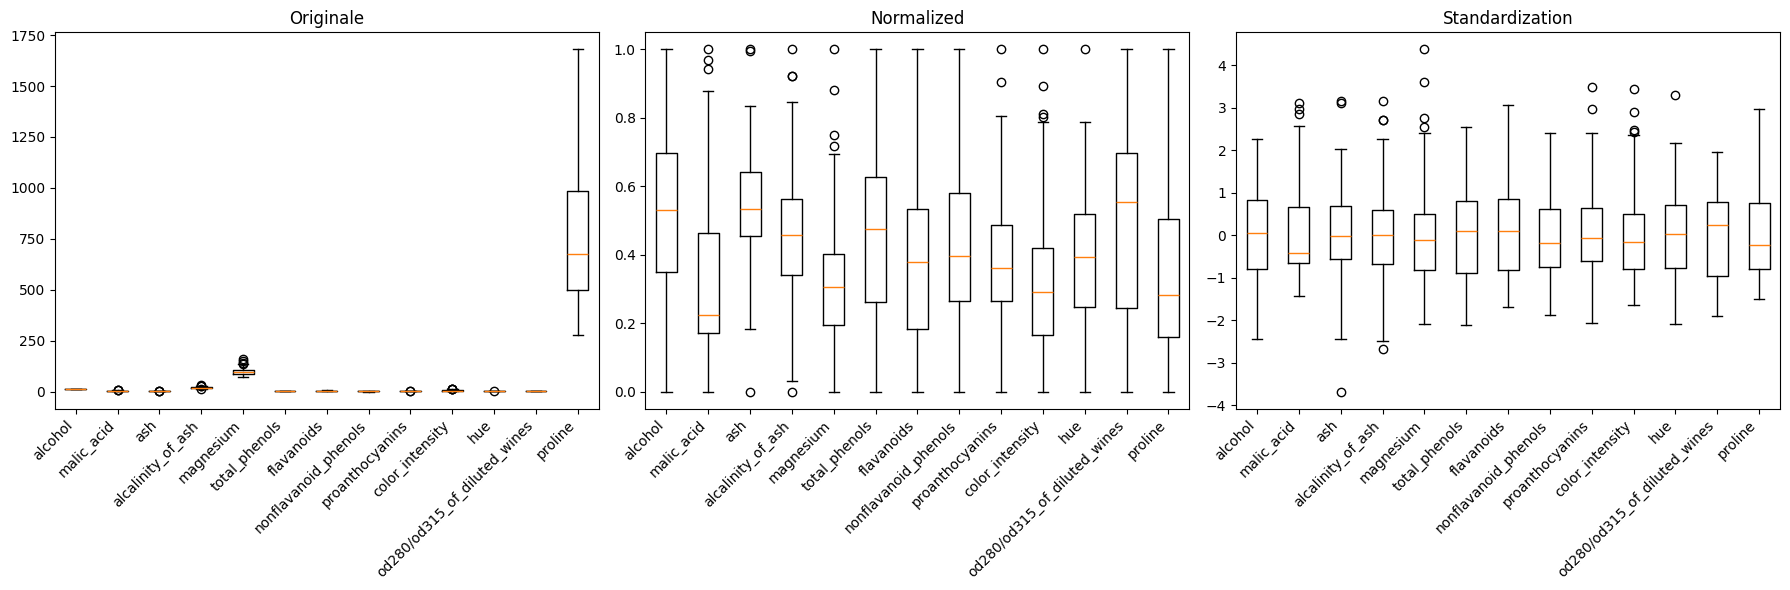

In [8]:
plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.boxplot(X.values)
plt.title("Originale")
plt.xticks(ticks=range(1, len(X.columns) + 1), labels = X.columns, rotation = 45, ha = "right")


plt.subplot(1,3,2)
plt.boxplot(X_norm.values)
plt.title("Normalized")
plt.xticks(ticks=range(1, len(X.columns) + 1), labels = X.columns, rotation = 45, ha = "right")

plt.subplot(1,3,3)
plt.boxplot(X_std.values)
plt.title("Standardization")
plt.xticks(ticks=range(1, len(X.columns) + 1), labels = X.columns, rotation = 45, ha = "right")


plt.tight_layout()
plt.show()


TRAINING

In [ ]:
datasets = [X, X_norm, X_std]

kmeans, kmeans_norm, kmeans_std = [KMeans(n_clusters = 3, random_state = 42).fit(data) for data in datasets]

model = [kmeans, kmeans_norm, kmeans_std]

def cluster_accurancy(Y,labels):
    labels_pred = np.zeros_like(labels)
    for cluster in np.unique(labels):
        mask = labels == cluster
        most_common = np.bincount(y[mask]).argmax()
        labels_pred[mask] = most_common
    return np.mean(labels_pred == y)


In [ ]:
titles = ["Originale", "Normalized", "Standardized"]

for title, model in zip(titles, models):
    acc = cluster_accuracy(Y, model.labels_)
    print(f"Accuracy KMeans ({titles}): )